# Regresión: KNN

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "knn"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,KNN
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |

En las tres, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** El modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Se exploraron 20 combinaciones. El número de vecinos va de 15 a 300: con un target tan ruidoso, promediar pocos vecinos sobreajusta. También se prueban los pesos (`uniform` o `distance`, que pondera más a los vecinos cercanos) y la distancia (`p=1` Manhattan, `p=2` euclídea). Con `weights="distance"` la predicción de entrenamiento reproduce cada y, así que los residuos de entrenamiento son 0 y el smearing no corrige nada.

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
n_neighbors,entero entre 15 y 300
weights,"uniform, distance"
p,"1, 2"


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.9578 ± 0.5355  R² = 0.1884  (5 s)
✓ sqrt + smearing    RMSE = 6.9697 ± 0.5131  R² = 0.1852  (3 s)
✓ log1p + smearing   RMSE = 6.9359 ± 0.5117  R² = 0.1932  (3 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.958 ± 0.536,4.873 ± 0.196,0.188 ± 0.016,5.0
sqrt + smearing,6.970 ± 0.513,4.946 ± 0.189,0.185 ± 0.015,3.0
log1p + smearing,6.936 ± 0.512,4.910 ± 0.192,0.193 ± 0.013,3.0


Las tres variantes quedan muy cerca. log1p obtiene el menor RMSE (6.936 ± 0.512) y el mayor R² (0.193), seguida del nativo (6.958, R² = 0.188) y de sqrt (6.970, R² = 0.185). En MAE, en cambio, gana el nativo (4.873). Ninguna variante mejora a la regresión lineal (6.900).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,n_neighbors,p,weights
Variante,,,
Nativo,102,1,distance
sqrt + smearing,63,1,uniform
log1p + smearing,149,1,uniform


Todas las variantes prefieren muchos vecinos (entre 63 y 149) y la distancia Manhattan (`p=1`). El BDI es muy ruidoso, así que hace falta promediar a muchos adolescentes para estimar su media. El nativo pondera por distancia (`weights="distance"`) con 102 vecinos; las variantes transformadas usan pesos uniformes.

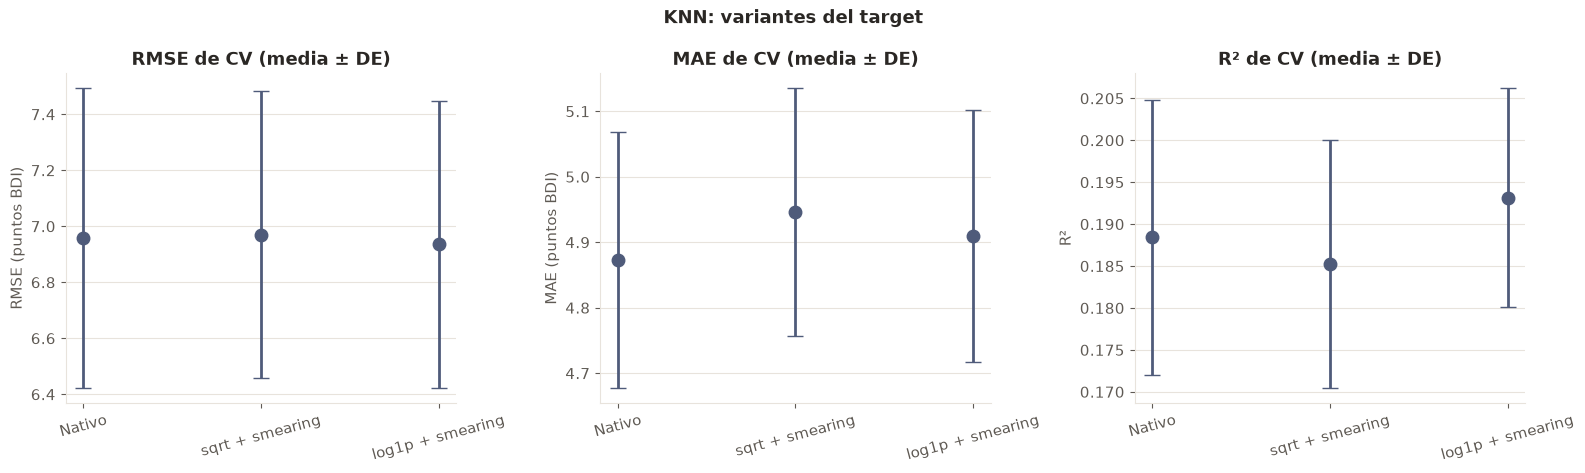

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

En la gráfica, las diferencias entre variantes son mínimas frente a la variabilidad entre folds (≈ 0.5 en RMSE): las barras de desviación se solapan por completo.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (log1p + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,4.640,-2.661,7.553,4.751,0.049
Con smearing,7.136,-0.166,6.955,4.910,0.194


log1p es la variante con el sesgo de retransformación más fuerte. Sin smearing, la media predicha es 4.64, 2.66 puntos por debajo de la real (7.30), y el R² cae a 0.049. Con la corrección, la media sube a 7.14 (sesgo de −0.17), el RMSE baja de 7.553 a 6.955 y el R² sube a 0.194. Como log1p usa pesos uniformes, los residuos de entrenamiento no son nulos y la corrección funciona. Con `weights="distance"`, la predicción de entrenamiento reproduce cada valor y el smearing no habría corregido nada.

### Selección del Mejor Modelo KNN

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,KNN
Variante ganadora,Nativo
RMSE de CV,6.9578 ± 0.5355
MAE de CV,4.8729 ± 0.1956
R² de CV,0.1884 ± 0.0164
Hiperparámetros,"n_neighbors=102, p=1, weights=distance"
Criterio,"El menor RMSE medio de CV es el de 'log1p + smearing' (6.9359 ± 0.5117), pero 'Nativo' es más simple y su RMSE (6.9578) está a solo 0.0218 puntos, menos que la desviación estándar de CV de la ganadora (0.5117). Por la regla de empate se elige 'Nativo'."


log1p tiene el menor RMSE medio (6.9359), pero el nativo está a solo 0.022 puntos, muy por debajo de la desviación entre folds (0.512). Por la regla de empate se elige el nativo, que además no depende del smearing y tiene el menor MAE.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/knn: resultados_cv.csv, ganador.json y knn_nativo.joblib
